# DGCA domestic airlines: cleaning
Step 2 of 3. Run order: `dgca_download_pipeline.ipynb`, then **this notebook**, then `dgca_dashboard_v5.ipynb`. Reads `data/interim/`, writes `data/clean/`.

**Files written here**

| File in `data/clean/` | What it is | Read by the dashboard? |
|---|---|---|
| `dgca_domestic_clean_<date>.parquet` | scheduled domestic flights, one row per airline-month | yes |
| `total_domestic_reconciliation_<date>.csv` | airlines' sum vs DGCA's Total Domestic; sets the last month analysed | yes |
| `cleaning_log_<date>.csv` | one line per cleaning step, with rows affected | yes |
| `dgca_international_clean_<date>.parquet` | scheduled international rows behind section 7 of the dashboard | a copy: the dashboard applies the same steps to the interim table |
| `dgca_citypair_routes_<date>.csv` | one row per route per month, behind section 6 | a copy: the dashboard applies the same steps to the raw file |
| `zero_filled_months_<date>.csv` | every group-month the dashboard sets to zero, and why | a record of what it does |
| `outlier_review_<date>.csv`, `outlier_diagnosis_<date>.csv`, `validation_rule_flags_<date>.csv` | checks that changed nothing | no |
| `unit_check_flags_<date>.csv` | rows whose implied trip length or aircraft speed looks wrong | no |
| `data_dictionary_<date>.csv` | column, dtype, unit, source and allowed range for the three tables | no |

**How to read the cleaning log.** Each line is one step. `rows_before` and `rows_after` count rows in the table at that step, and `rows_affected` counts rows removed or changed by it. A check or a decision to keep values as reported has `rows_affected` = 0, and its note says how many rows it looked at. Stage 2 to 4 steps are the ones the dashboard notebook applies when it builds the page; they are computed here with the same rules and written to the log so the whole path is in one place.

## 1. Load the interim table

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

_here = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in [_here, *_here.parents] if (p / "data" / "interim").is_dir())
RAW, INTERIM, CLEAN = (PROJECT_ROOT / "data" / d for d in ("raw", "interim", "clean"))
CLEAN.mkdir(parents=True, exist_ok=True)
latest = lambda folder, pat: sorted(folder.glob(pat))[-1]

src = latest(INTERIM, "dgca_domestic_airline_monthly_*.csv")
raw = pd.read_csv(src)
TODAY = src.stem.rsplit("_", 1)[-1]     # the clean files carry the same date as the interim file they come from

METRICS = ["Aircraft Number", "Aircraft Hours", "Aircraft Kilometres", "Passenger Number", "Passenger Kilometers", "Seat Kilometers",
           "Passenger Load Factor", "Freight", "Mail", "Total Cargo", "Passenger Tonne Kilometer", "Mail Tonne Kilometer",
           "Freight Tonne Kilometer", "Total Tonne Kilometer", "Available Tonne Kilometer", "Weight Load Factor"]
required = ["Type", "Airline", "Year", "Month", "Source File", "Source Sheet"] + METRICS
missing = [c for c in required if c not in raw.columns]
if missing: raise ValueError(f"Input table is missing expected columns: {missing}")
for c in METRICS:
    raw[c] = pd.to_numeric(raw[c].astype("string").str.replace(",", "", regex=False).str.strip().replace("-", pd.NA), errors="coerce")
raw["Year"], raw["Month"] = raw["Year"].astype(int), raw["Month"].astype(int)
if not raw.Month.between(1, 12).all(): raise ValueError("Month values must be between 1 and 12.")

print("input:", src.name, "| shape:", raw.shape, "| source files:", raw["Source File"].nunique(), "| years:", raw.Year.min(), "-", raw.Year.max())
print("traffic types:", raw.Type.value_counts().to_dict())

input: dgca_domestic_airline_monthly_2026-11-01.csv | shape: (5844, 22) | source files: 142 | years: 2017 - 2026
traffic types: {'ScheduledDomestic': 1704, 'NonScheduledDomestic': 1524, 'ScheduledInternational': 1356, 'NonScheduledInternational': 1260}


## 2. Where are the holes?
DGCA's sheets list every section for every airline, so most "missing data" is empty template rows, not real gaps.

row_kind                   empty_template  live  live_but_no_pax   All
Type                                                                  
NonScheduledDomestic                  759   761                4  1524
NonScheduledInternational             957   288               15  1260
ScheduledDomestic                     278  1424                2  1704
ScheduledInternational                816   540                0  1356
All                                  2810  3013               21  5844


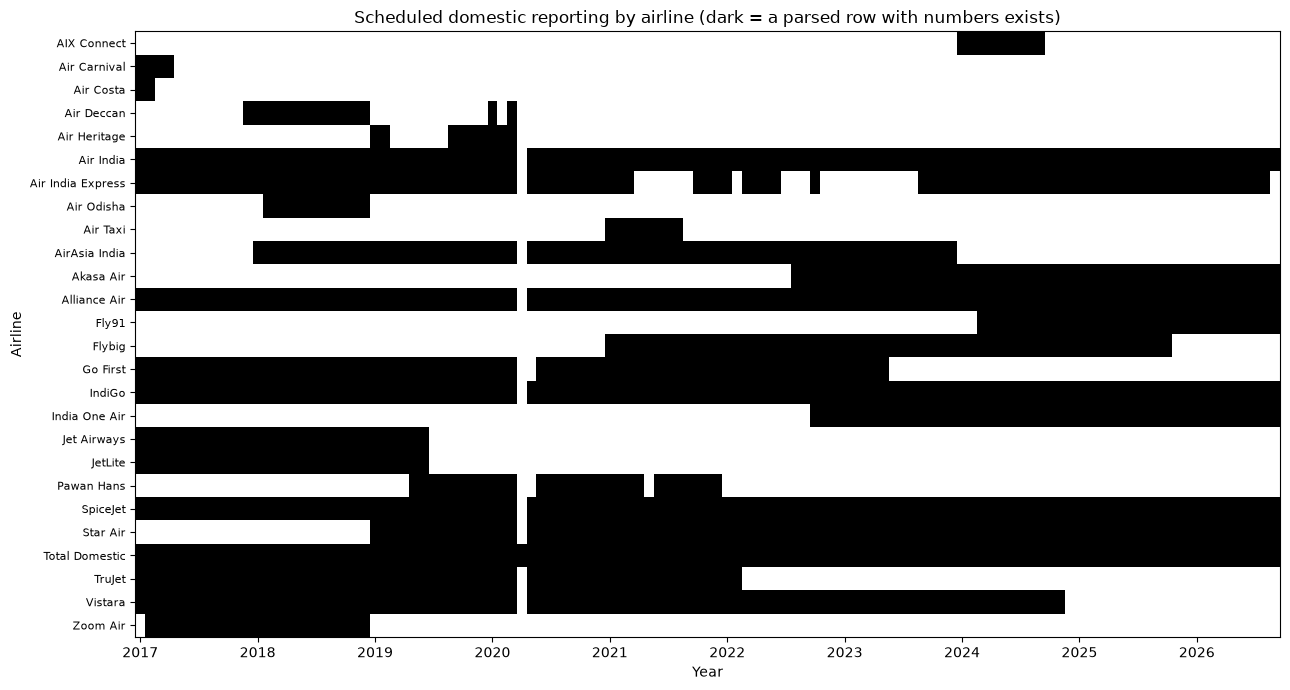

In [2]:
raw["row_kind"] = np.where(raw[METRICS].isna().all(axis=1), "empty_template", np.where(raw["Passenger Number"].isna(), "live_but_no_pax", "live"))
print(pd.crosstab(raw.Type, raw.row_kind, margins=True).to_string())

sd_live = raw[(raw.row_kind != "empty_template") & (raw.Type == "ScheduledDomestic")].copy()
sd_live["Date"] = pd.to_datetime(dict(year=sd_live.Year, month=sd_live.Month, day=1))
pres = sd_live.assign(reported=1).pivot_table(index="Airline", columns="Date", values="reported", aggfunc="max")
fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(pres.notna().astype(int).values, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(pres))); ax.set_yticklabels(pres.index, fontsize=8)
ticks = [i for i, d in enumerate(pres.columns) if d.month == 1]
ax.set_xticks(ticks); ax.set_xticklabels([pres.columns[i].year for i in ticks])
ax.set_title("Scheduled domestic reporting by airline (dark = a parsed row with numbers exists)"); ax.set_xlabel("Year"); ax.set_ylabel("Airline")
plt.tight_layout(); plt.show()

## 3. Stage 1: from the parsed table to the clean table
The first three step names and their order are read by the dashboard's "What cleaning did to the data" chart. Keep them as they are.

In [3]:
log = []
def step(stage, name, before, after, affected=None, note=""):
    affected = int(before - after) if affected is None else int(affected)
    log.append({"stage": stage, "step": name, "rows_before": int(before), "rows_after": int(after), "rows_affected": affected, "note": note})
    print(f"{name}: {before:,} -> {after:,} | affected {affected:,} | {note}")
S1 = "1 airline table"

df = raw.drop(columns="row_kind").copy()
df["Airline"] = df["Airline"].astype("string").str.strip()
df["Airline_key"] = df["Airline"].str.casefold().str.replace(r"[_-]+", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()

n = len(df); df = df[~df[METRICS].isna().all(axis=1)].copy()
step(S1, "remove empty template rows", n, len(df), note="All 16 metric columns were empty.")

n = len(df); df = df[df.Type.isin(["ScheduledDomestic", "NonScheduledDomestic"])].copy()
step(S1, "retain domestic traffic sections", n, len(df), note="International sections removed from this table; stage 3 uses them.")

n = len(df); df = df[df.Type.eq("ScheduledDomestic")].copy()
step(S1, "remove non-scheduled domestic rows", n, len(df), note="Charter and other unscheduled flying is out of scope.")

total_mask = df.Airline_key.eq("total domestic")
totals = df[total_mask].drop(columns="Airline_key").copy()
n = len(df); df = df[~total_mask].copy()
step(S1, "separate Total Domestic aggregate", n, len(df), note="DGCA's own total, kept aside for the reconciliation check.")

KEEP = ["Type", "Airline", "Year", "Month", "Source File", "Source Sheet", "Aircraft Number", "Aircraft Hours", "Aircraft Kilometres",
        "Passenger Number", "Passenger Kilometers", "Seat Kilometers", "Passenger Load Factor"]
dropped = [c for c in METRICS if c not in KEEP]
df, totals = df[KEEP].copy(), totals[KEEP].copy()
step(S1, "remove cargo, mail and tonne columns", len(df), len(df), 0, f"{len(dropped)} columns removed; no rows removed: " + ", ".join(dropped) + ".")

df["Date"] = pd.to_datetime(dict(year=df.Year, month=df.Month, day=1))
totals["Date"] = pd.to_datetime(dict(year=totals.Year, month=totals.Month, day=1))
step(S1, "add Date column", len(df), len(df), len(df), "First day of the month, built from Year and Month, added to every row.")

dupes = df[df.duplicated(["Type", "Airline", "Date"], keep=False)]
if not dupes.empty: raise ValueError("Duplicate airline-month keys found:\n" + dupes[["Airline", "Date", "Source File"]].to_string())
step(S1, "check for duplicate airline-months", len(df), len(df), 0, "Check only: no duplicate (Type, Airline, Date) keys.")

GROUP = {"Air India": "Air India Group", "Air India Express": "Air India Group", "Vistara": "Air India Group", "AirAsia India": "Air India Group",
         "AIX Connect": "Air India Group", "JetLite": "Jet Airways"}
n_air = df.Airline.nunique()
df["Group"] = df.Airline.map(GROUP).fillna(df.Airline)
step(S1, "map historical airline brands to groups", len(df), len(df), (df.Group != df.Airline).sum(), f"Group column added; {n_air} airline labels become {df.Group.nunique()} groups. Airline column kept.")
display(df[df.Group != df.Airline].groupby(["Group", "Airline"]).size().rename("rows").to_frame())

remove empty template rows: 5,844 -> 3,034 | affected 2,810 | All 16 metric columns were empty.
retain domestic traffic sections: 3,034 -> 2,191 | affected 843 | International sections removed from this table; stage 3 uses them.
remove non-scheduled domestic rows: 2,191 -> 1,426 | affected 765 | Charter and other unscheduled flying is out of scope.
separate Total Domestic aggregate: 1,426 -> 1,309 | affected 117 | DGCA's own total, kept aside for the reconciliation check.
remove cargo, mail and tonne columns: 1,309 -> 1,309 | affected 0 | 9 columns removed; no rows removed: Freight, Mail, Total Cargo, Passenger Tonne Kilometer, Mail Tonne Kilometer, Freight Tonne Kilometer, Total Tonne Kilometer, Available Tonne Kilometer, Weight Load Factor.
add Date column: 1,309 -> 1,309 | affected 1,309 | First day of the month, built from Year and Month, added to every row.
check for duplicate airline-months: 1,309 -> 1,309 | affected 0 | Check only: no duplicate (Type, Airline, Date) keys.
map hi

rows
Group           Airline                
Air India Group AIX Connect           9
                Air India           116
                Air India Express    95
                AirAsia India        71
                Vistara              94
Jet Airways     JetLite              30

## 3b. Duplicates: exact and across sources
**Matching rules**
- *Exact duplicates:* the same values in every column, and separately the same (Type, Airline, Date) key.
- *Same airline under different names:* file-name spellings are mapped to one name when parsing (`airline_name_variants`), then brands to a group using `GROUP` above.
- *Same city under different names:* the rules in stage 4 (`canon`), and routes are merged when both ends match after that.
- *Across sources:* a DGCA row and a Vonter row are the same record when Type, Airline, Year and Month all match. Vonter's airline rows are used only to check our parser and are never added to the clean table, so they cannot be counted twice.

**Repeated months.** The table below lists rows where an airline reports exactly the same numbers in two different months. These are not duplicate records: each sits under its own month in DGCA's workbook, and the Vonter parse shows the same values. They look like copy errors in the source, but the source does not show which month's numbers are right, so they are kept as reported.

In [4]:
n_exact = int(df.duplicated(KEEP).sum())
number_cols = ["Aircraft Number", "Aircraft Hours", "Aircraft Kilometres", "Passenger Number", "Passenger Kilometers", "Seat Kilometers", "Passenger Load Factor"]
n_same_numbers = int(df[df["Passenger Number"].gt(0)].duplicated(["Airline"] + number_cols).sum())
print("exact duplicate rows:", n_exact, "| rows with traffic repeating an earlier month's numbers for the same airline:", n_same_numbers)
traffic = df[df["Passenger Number"].gt(0)]
repeats = traffic[traffic.duplicated(["Airline"] + number_cols, keep=False)].sort_values(["Airline", "Passenger Number", "Date"])
display(repeats[["Airline", "Date"] + number_cols[:6]])
step(S1, "check for exact duplicate rows", len(df), len(df), n_exact, f"Check only: {n_exact} exact duplicates; {n_same_numbers} traffic rows repeat another month's numbers ({', '.join(repeats.Airline.unique())}); kept as reported.")

xs = pd.read_csv(latest(INTERIM, "cross_source_comparison_*.csv"), low_memory=False)
both = xs[xs["_merge"].eq("both")]
n_equal = int(np.isclose(both["Passenger Number_dgca"].astype(float), both["Passenger Number_gh"].astype(float), equal_nan=True).sum())
display(pd.read_csv(latest(INTERIM, "cross_source_match_classes_*.csv")))
step(S1, "match records across DGCA and Vonter", len(df), len(df), 0, f"Check only: {len(both):,} records match on Type, Airline, Year, Month; passengers agree on {n_equal:,}. Vonter rows are not added, so none are removed.")

exact duplicate rows: 0 | rows with traffic repeating an earlier month's numbers for the same airline: 4


,Airline,Date,Aircraft Number,Aircraft Hours,Aircraft Kilometres,Passenger Number,Passenger Kilometers,Seat Kilometers
3397,Alliance Air,2022-02-01,2620.0,3302.0,1819.0,111715.0,46365.0,64487.0
3402,Alliance Air,2022-07-01,2620.0,3302.0,1819.0,111715.0,46365.0,64487.0
3394,Alliance Air,2021-11-01,2907.0,3811.0,2218.0,120306.0,54410.0,79476.0
3399,Alliance Air,2022-04-01,2907.0,3837.183333,2217.695,120306.0,48693.097,72765.28
3401,Alliance Air,2022-06-01,2907.0,3837.183333,2217.695,120306.0,48693.097,72765.28
3404,Alliance Air,2022-09-01,2907.0,3811.0,2218.0,120306.0,54410.0,79476.0
3395,Alliance Air,2021-12-01,3085.0,3958.0,2263.0,125358.0,56284.0,84022.0
3403,Alliance Air,2022-08-01,3085.0,3958.0,2263.0,125358.0,56284.0,84022.0


check for exact duplicate rows: 1,309 -> 1,309 | affected 0 | Check only: 0 exact duplicates; 4 traffic rows repeat another month's numbers (Alliance Air); kept as reported.


,match_class,records
0,"cargo carrier, excluded by design",533
1,empty template row (nothing to compare),1037
2,international section (the GitHub domestic fil...,1797
3,live domestic row missing from the GitHub copy...,9
4,matched,2966
5,month newer than the GitHub copy (its commit p...,35


match records across DGCA and Vonter: 1,309 -> 1,309 | affected 0 | Check only: 2,966 records match on Type, Airline, Year, Month; passengers agree on 2,966. Vonter rows are not added, so none are removed.


## 4. Missing values: what is left, and what we decided
Nothing is imputed in the clean table. Zero-traffic months stay as DGCA reported them, and load factor stays empty where it would be 0/0.

In [5]:
core = ["Aircraft Number", "Aircraft Hours", "Aircraft Kilometres", "Passenger Number", "Passenger Kilometers", "Seat Kilometers", "Passenger Load Factor"]
display(df[core].isna().sum().rename("missing_cells").to_frame())
zero_flight = df["Passenger Number"].eq(0) & df["Passenger Kilometers"].eq(0) & df["Seat Kilometers"].eq(0)
lf_na = df["Passenger Load Factor"].isna()
gaps = df[df[core].isna().any(axis=1) & ~zero_flight]
print("rows with a real gap in a core column:"); display(gaps[["Airline", "Date"] + core])

skp = df["Seat Kilometers"].where(df["Seat Kilometers"] > 0)
lf_calc = df["Passenger Kilometers"] / skp * 100
valid = df["Passenger Load Factor"].notna() & lf_calc.notna()
diff = (df.loc[valid, "Passenger Load Factor"] - lf_calc[valid]).abs()
print(f"reported vs computed load factor on {int(valid.sum())} rows: mean absolute difference {diff.mean():.3f} points, largest {diff.max():.3f}")

step(S1, "keep reported zero-traffic rows", len(df), len(df), 0, f"Kept unchanged: {int(zero_flight.sum())} rows with zero passengers, passenger-km and seat-km.")
step(S1, "leave undefined load factors empty", len(df), len(df), 0, f"Kept unchanged: {int((zero_flight & lf_na).sum())} zero-traffic rows where load factor is 0/0.")
step(S1, "leave real gaps empty, no imputation", len(df), len(df), 0, f"Kept unchanged: {len(gaps)} rows with a missing core value, {int((gaps['Passenger Number'].isna()).sum())} of them with no passenger count.")

,missing_cells
Aircraft Number,1
Aircraft Hours,4
Aircraft Kilometres,2
Passenger Number,1
Passenger Kilometers,3
Seat Kilometers,2
Passenger Load Factor,18


rows with a real gap in a core column:


,Airline,Date,Aircraft Number,Aircraft Hours,Aircraft Kilometres,Passenger Number,Passenger Kilometers,Seat Kilometers,Passenger Load Factor
2846,Air Deccan,2020-03-01,<NA>,<NA>,<NA>,58.0,<NA>,<NA>,<NA>
3152,Air Odisha,2018-09-01,64.0,<NA>,<NA>,295.0,<NA>,<NA>,<NA>
3175,Air Taxi,2021-08-01,1.0,0.916667,0.2296,<NA>,<NA>,0.689,0.0
3593,Go First,2020-06-01,831.0,<NA>,883.0,88513.0,95199.0,164290.0,57.945706
4410,Vistara,2020-07-01,993.0,<NA>,1121.492,88235.0,100586.603,189529.484,53.071744


reported vs computed load factor on 1290 rows: mean absolute difference 0.000 points, largest 0.005
keep reported zero-traffic rows: 1,309 -> 1,309 | affected 0 | Kept unchanged: 16 rows with zero passengers, passenger-km and seat-km.
leave undefined load factors empty: 1,309 -> 1,309 | affected 0 | Kept unchanged: 16 zero-traffic rows where load factor is 0/0.
leave real gaps empty, no imputation: 1,309 -> 1,309 | affected 0 | Kept unchanged: 5 rows with a missing core value, 1 of them with no passenger count.


In [6]:
# Pattern and test, on domestic rows that hold at least one number and are not DGCA totals
from scipy import stats
live_dom = raw[raw.row_kind.ne("empty_template") & raw.Type.isin(["ScheduledDomestic", "NonScheduledDomestic"]) & ~raw.Airline.str.lower().str.contains("total")].copy()
print("missing cells per column, by traffic type:"); display(live_dom.groupby("Type")[core].agg(lambda s: int(s.isna().sum())).T)
live_dom["any_missing"] = live_dom[core].isna().any(axis=1)
print("rows with any missing core value:"); tab = pd.crosstab(live_dom.Type, live_dom.any_missing); display(tab)
odds, p_type = stats.fisher_exact(tab)
print(f"Fisher exact test, any missing vs traffic type: odds ratio {odds:.2f}, p = {p_type:.2g}")
sd_live_y = live_dom[live_dom.Type.eq("ScheduledDomestic")]
tab_y = pd.crosstab(sd_live_y.Year, sd_live_y.any_missing); display(tab_y.T)
chi2, p_year, dof, _ = stats.chi2_contingency(tab_y)
print(f"Chi-square test, any missing vs year (scheduled domestic): chi2 = {chi2:.1f}, dof = {dof}, p = {p_year:.2g}. Expected counts are small, so read this one as a rough guide.")

missing cells per column, by traffic type:


Type,NonScheduledDomestic,ScheduledDomestic
Aircraft Number,0,1
Aircraft Hours,2,4
Aircraft Kilometres,0,2
Passenger Number,4,1
Passenger Kilometers,5,3
Seat Kilometers,4,2
Passenger Load Factor,82,18


rows with any missing core value:


any_missing,False,True
Type,,
NonScheduledDomestic,564,84
ScheduledDomestic,1288,21


Fisher exact test, any missing vs traffic type: odds ratio 0.11, p = 3.9e-24


Year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
any_missing,,,,,,,,,,
False,137,155,142,121,144,124,129,138,118,80
True,1,12,4,3,1,0,0,0,0,0


Chi-square test, any missing vs year (scheduled domestic): chi2 = 45.7, dof = 9, p = 6.8e-07. Expected counts are small, so read this one as a rough guide.


### Mechanism and treatment of each kind of missing value

| Kind of missing value | Rows | Likely mechanism | What we did | Why |
|---|---|---|---|---|
| Whole row empty (template rows) | see log | MNAR, structural: blank because the airline did not fly that section or month, so the absence depends on the missing value itself | Deleted | The row holds no measurement, and imputing would invent flying |
| Load factor empty where passengers and seat-km are zero | see log | Structural: load factor is 0/0, so no value exists | Kept empty | There is nothing to estimate |
| Real gaps in otherwise reported rows | see table above | Not MCAR: the Fisher test shows missingness depends on traffic type, which is observed, so MAR is the working assumption within what we can test. MNAR cannot be ruled out from the data | Kept empty in the clean table | Very few rows, all listed above, and the gaps fall in 2017 to 2021. Model-based imputation on so few rows would add false precision to official figures |
| Month with no report while flying was suspended | see stage 2 and 3 | Structural: an outside event, so the value is known to be zero | Filled with zero in the dashboard only (`zero_filled_months`) | Deterministic imputation that fits the mechanism; it leaves the clean table as reported |

No statistical imputation is used. These tests show association; they cannot prove MAR or MNAR.

## 5. Outliers and hard-rule checks
These checks change nothing. A row is flagged if its passengers are far from the airline's rolling median (robust z above 6 and more than 40% away). Each flagged row is then tested for a recording error and given a likely cause.

In [7]:
def screen(g, col="Passenger Number", win=5):
    g = g.sort_values("Date").copy()
    s = g.set_index("Date")[col].astype(float)
    med = s.rolling(win, center=True, min_periods=3).median()
    resid = np.log1p(s.clip(lower=0)) - np.log1p(med.clip(lower=0))
    center = resid.median(); mad = (resid - center).abs().median()
    z = 0.6745 * (resid - center) / mad if pd.notna(mad) and mad > 0 else pd.Series(np.nan, index=resid.index)
    return pd.DataFrame({"z": z, "dev_vs_median": (s / med - 1).where(med > 0)}).reset_index()

sdm = df.sort_values(["Airline", "Date"])
scr = pd.concat([screen(g).assign(Airline=a) for a, g in sdm.groupby("Airline")], ignore_index=True)
flag = sdm.merge(scr, on=["Airline", "Date"], how="left")
flag = flag[(flag.z.abs() > 6) & (flag.dev_vs_median.abs() > 0.4)].copy()
flag["covid_window"] = flag.Date.between("2020-03-01", "2020-06-30") | flag.Date.between("2021-04-01", "2021-06-30")
out = flag[["Airline", "Date", "Passenger Number", "Passenger Load Factor", "z", "dev_vs_median", "covid_window", "Source File", "Source Sheet"]].sort_values("z")
out.to_csv(CLEAN / f"outlier_review_{TODAY}.csv", index=False)
step(S1, "flag statistical outliers for review", len(df), len(df), 0, f"Check only: {len(out)} rows flagged ({int(out.covid_window.sum())} in COVID windows); none changed.")

rules = {"load factor outside 0-100": df["Passenger Load Factor"].notna() & ~df["Passenger Load Factor"].between(0, 100),
         "passenger kilometres exceed seat kilometres": df["Passenger Kilometers"].notna() & df["Seat Kilometers"].notna() & (df["Passenger Kilometers"] > df["Seat Kilometers"]),
         "negative retained metric": df[core].lt(0).any(axis=1),
         "zero passengers but aircraft count positive": df["Passenger Number"].eq(0) & df["Aircraft Number"].gt(0)}
rule_rows = [df.loc[m, ["Type", "Airline", "Date", "Source File", "Source Sheet"] + core].assign(rule=name) for name, m in rules.items() if m.any()]
rule_flags = pd.concat(rule_rows, ignore_index=True) if rule_rows else pd.DataFrame(columns=["rule", "Type", "Airline", "Date", "Source File", "Source Sheet"] + core)
rule_flags = rule_flags[["rule"] + [c for c in rule_flags.columns if c != "rule"]]
rule_flags.to_csv(CLEAN / f"validation_rule_flags_{TODAY}.csv", index=False)
step(S1, "check hard rules", len(df), len(df), 0, f"Check only: {len(rules)} rules, {len(rule_flags)} rows broke one.")

flag statistical outliers for review: 1,309 -> 1,309 | affected 0 | Check only: 53 rows flagged (20 in COVID windows); none changed.
check hard rules: 1,309 -> 1,309 | affected 0 | Check only: 4 rules, 0 rows broke one.


In [8]:
# OUTLIER DIAGNOSIS: for every flagged row, test whether it is a recording error, then name the likely cause
gh = pd.read_csv(latest(RAW / "github", "vonter_domestic_carrier_*.csv"))
sd_ = df
d = out.merge(sd_[["Airline", "Date", "Passenger Kilometers", "Seat Kilometers", "Year", "Month"]], on=["Airline", "Date"], how="left")
for c in ["Passenger Number", "Passenger Load Factor", "Passenger Kilometers", "Seat Kilometers"]: d[c] = d[c].astype(float)

# test 1: average trip length must be plausible (50 km allows helicopter hops), and load factor must equal passenger-km / seat-km x 100
d["avg_trip_km"] = d["Passenger Kilometers"] * 1000 / d["Passenger Number"].where(d["Passenger Number"] > 0)
d["trip_ok"] = d.avg_trip_km.between(50, 3500) | d.avg_trip_km.isna()
lf_c = d["Passenger Kilometers"] / d["Seat Kilometers"].where(d["Seat Kilometers"] > 0) * 100
d["lf_ok"] = ((lf_c - d["Passenger Load Factor"]).abs() < 0.1) | lf_c.isna()

# test 2: Vonter's separate parse of the same files must show the same number. A missing GitHub record is not a pass: nothing was compared.
g2 = gh[gh.Type == "ScheduledDomestic"][["Airline", "Year", "Month", "Passenger Number"]].rename(columns={"Passenger Number": "gh_pax"})
d = d.merge(g2, on=["Airline", "Year", "Month"], how="left")
d["github_check"] = np.where(d.gh_pax.isna(), "no GitHub record", np.where((d.gh_pax - d["Passenger Number"]).abs() < 1, "match", "differs"))
d["github_ok"] = d.github_check.ne("differs")

def cause(r):
    s = sd_[sd_.Airline == r.Airline].set_index("Date")["Passenger Number"].fillna(0)
    later, earlier = s[s.index > r.Date], s[s.index < r.Date]
    if r.Date >= df.Date.max(): return "newest month in the data: may still be provisional"
    if r.covid_window: return "COVID-19 restrictions (Mar-Jun 2020 / Apr-Jun 2021 windows)"
    if (later > 0).sum() == 0: return "no later traffic in the data: airline stopped, merged or stopped reporting (check which)"
    if (earlier > 0).sum() == 0: return "launch month: first traffic, partial month"
    if r["Passenger Number"] == 0: return "temporary suspension: zero month between operating months"
    if s[s > 0].median() < 25000: return "small carrier: a few hundred passengers move the percentage a lot"
    return "no rule matched: check news and the neighbouring months"
d["likely_cause"] = d.apply(cause, axis=1)
EVENT_NOTES = {("Jet Airways", "2019-05"): "Jet Airways suspended operations in April 2019",
               ("Go First", "2023-05"): "Go First stopped flying in early May 2023 (insolvency filing)",
               ("Vistara", "2024-11"): "Vistara merged into Air India in November 2024",
               ("Akasa Air", "2022-08"): "Akasa Air began flying in August 2022"}
d["event_note"] = [EVENT_NOTES.get((a, t.strftime("%Y-%m")), "") for a, t in zip(d.Airline, d.Date)]
error_free = d.trip_ok & d.lf_ok & d.github_ok
d["diagnosis"] = np.where(~error_free, "possible recording error: investigate", np.where(d.likely_cause.str.startswith("no rule"), "real value, cause still to confirm", "real value"))
d["review_status"] = np.select([~error_free, d.event_note.ne(""), d.likely_cause.str.startswith("no rule")],
                               ["possible recording error: investigate", "plausible: named event, cite a source", "unresolved"],
                               default="plausible: pattern fits the cause (rule-based, not verified)")
d["action"] = np.where(d.diagnosis.str.startswith("possible"), "investigate", "keep as reported")
diag_cols = ["Airline", "Date", "Passenger Number", "dev_vs_median", "avg_trip_km", "trip_ok", "lf_ok", "github_check", "likely_cause", "event_note", "diagnosis", "review_status", "action"]
d[diag_cols].round({"dev_vs_median": 2, "avg_trip_km": 0}).to_csv(CLEAN / f"outlier_diagnosis_{TODAY}.csv", index=False)
print(d.diagnosis.value_counts().to_string()); print(); print(d.review_status.value_counts().to_string()); print(); print(d.action.value_counts().to_string())

diagnosis
real value                            49
real value, cause still to confirm     4

review_status
plausible: pattern fits the cause (rule-based, not verified)    45
plausible: named event, cite a source                            4
unresolved                                                       4

action
keep as reported    53


In [9]:
pd.set_option("display.max_rows", 120, "display.max_colwidth", 70, "display.width", 250)
print("every flagged row, with its diagnosis and action:"); display(d[diag_cols].round({"dev_vs_median": 2, "avg_trip_km": 0}))

every flagged row, with its diagnosis and action:


,Airline,Date,Passenger Number,dev_vs_median,avg_trip_km,trip_ok,lf_ok,github_check,likely_cause,event_note,diagnosis,review_status,action
0,Jet Airways,2019-05-01,0.0,-1.00,NaN,True,True,match,"no later traffic in the data: airline stopped, merged or stopped r...",Jet Airways suspended operations in April 2019,real value,"plausible: named event, cite a source",keep as reported
1,SpiceJet,2020-05-01,48156.0,-0.86,1009.0,True,True,match,COVID-19 restrictions (Mar-Jun 2020 / Apr-Jun 2021 windows),,real value,"plausible: pattern fits the cause (rule-based, not verified)",keep as reported
2,AirAsia India,2020-05-01,21941.0,-0.84,1154.0,True,True,match,COVID-19 restrictions (Mar-Jun 2020 / Apr-Jun 2021 windows),,real value,"plausible: pattern fits the cause (rule-based, not verified)",keep as reported
3,Akasa Air,2022-08-01,23744.0,-0.74,592.0,True,True,match,"launch month: first traffic, partial month",Akasa Air began flying in August 2022,real value,"plausible: named event, cite a source",keep as reported
4,AirAsia India,2021-05-01,63532.0,-0.61,1102.0,True,True,match,COVID-19 restrictions (Mar-Jun 2020 / Apr-Jun 2021 windows),,real value,"plausible: pattern fits the cause (rule-based, not verified)",keep as reported
5,JetLite,2019-05-01,0.0,-1.00,NaN,True,True,match,"no later traffic in the data: airline stopped, merged or stopped r...",,real value,"plausible: pattern fits the cause (rule-based, not verified)",keep as reported
6,IndiGo,2020-05-01,142254.0,-0.89,994.0,True,True,match,COVID-19 restrictions (Mar-Jun 2020 / Apr-Jun 2021 windows),,real value,"plausible: pattern fits the cause (rule-based, not verified)",keep as reported
7,Alliance Air,2020-05-01,3772.0,-0.91,410.0,True,True,match,COVID-19 restrictions (Mar-Jun 2020 / Apr-Jun 2021 windows),,real value,"plausible: pattern fits the cause (rule-based, not verified)",keep as reported
8,SpiceJet,2021-05-01,198792.0,-0.56,1135.0,True,True,match,COVID-19 restrictions (Mar-Jun 2020 / Apr-Jun 2021 windows),,real value,"plausible: pattern fits the cause (rule-based, not verified)",keep as reported
9,Air India,2020-05-01,41595.0,-0.79,938.0,True,True,match,COVID-19 restrictions (Mar-Jun 2020 / Apr-Jun 2021 windows),,real value,"plausible: pattern fits the cause (rule-based, not verified)",keep as reported


## 5b. Units
Every workbook labels its units in the header, and all share the same units. As a check that the numbers really follow them, two values are computed: average trip length (passenger-km / passengers) and aircraft speed (aircraft-km / hours). Rows outside 50 to 3,500 km or 100 to 1,000 km/h are saved for review. They are not changed: the source gives no way to tell which column is wrong, and DGCA's figures stay as reported.

In [10]:
u = df[["Airline", "Date", "Passenger Number", "Passenger Kilometers", "Aircraft Kilometres", "Aircraft Hours", "Source File"]].copy()
for c in u.columns[2:6]: u[c] = u[c].astype(float)
u["avg_trip_km"] = u["Passenger Kilometers"] * 1000 / u["Passenger Number"].where(u["Passenger Number"] > 0)
u["implied_speed_kmh"] = u["Aircraft Kilometres"] * 1000 / u["Aircraft Hours"].where(u["Aircraft Hours"] > 0)
u["trip_flag"] = u.avg_trip_km.notna() & ~u.avg_trip_km.between(50, 3500)
u["speed_flag"] = u.implied_speed_kmh.notna() & ~u.implied_speed_kmh.between(100, 1000)
unit_flags = u[u.trip_flag | u.speed_flag].round({"avg_trip_km": 0, "implied_speed_kmh": 0})
unit_flags.to_csv(CLEAN / f"unit_check_flags_{TODAY}.csv", index=False)
display(unit_flags.groupby("Airline").agg(rows=("Date", "size"), first=("Date", "min"), last=("Date", "max"), trip_flags=("trip_flag", "sum"), speed_flags=("speed_flag", "sum"), lowest_speed=("implied_speed_kmh", "min"), highest_speed=("implied_speed_kmh", "max")))
step(S1, "check units with trip length and aircraft speed", len(df), len(df), 0, f"Check only: {int(u.trip_flag.sum())} rows with an odd trip length, {int(u.speed_flag.sum())} with an odd aircraft speed; none changed.")

,rows,first,last,trip_flags,speed_flags,lowest_speed,highest_speed
Airline,,,,,,,
Air Carnival,1,2017-04-01,2017-04-01,0,1,1879.0,1879.0
Air Deccan,2,2018-03-01,2018-09-01,0,2,3067.0,3411.0
Air India Express,2,2019-10-01,2023-11-01,0,2,2.0,1796.0
Air Odisha,1,2018-07-01,2018-07-01,1,0,242.0,242.0
AirAsia India,3,2023-09-01,2023-11-01,0,3,8.0,8.0
Flybig,13,2021-01-01,2022-03-01,0,13,29.0,6524.0
Pawan Hans,1,2021-08-01,2021-08-01,1,0,126.0,126.0
SpiceJet,2,2022-09-01,2022-12-01,0,2,1629.0,1680.0
Star Air,1,2023-07-01,2023-07-01,0,1,19010.0,19010.0


check units with trip length and aircraft speed: 1,309 -> 1,309 | affected 0 | Check only: 2 rows with an odd trip length, 26 with an odd aircraft speed; none changed.


## 6. Cross-check: do the airlines add up to DGCA's Total Domestic?
The last month within 2% of DGCA's own total is where the dashboard's airline analysis stops.

In [11]:
mine = df.groupby("Date")["Passenger Number"].sum(min_count=1).rename("sum_airlines")
if totals.duplicated("Date").any(): raise ValueError("Duplicate Total Domestic months found.")
tot = totals.set_index("Date")["Passenger Number"].rename("dgca_total")
rec = pd.concat([mine, tot], axis=1).dropna()
rec["ratio"] = rec.sum_airlines / rec.dgca_total.where(rec.dgca_total > 0)
rec["difference_pct"] = (rec.ratio - 1) * 100
rec["within_2pct"] = rec.difference_pct.abs() <= 2
rec.to_csv(CLEAN / f"total_domestic_reconciliation_{TODAY}.csv")
display(rec[~rec.within_2pct].round(3))
ANALYSIS_END = rec.index[rec.within_2pct].max()
print("last month within 2% of DGCA's total:", f"{ANALYSIS_END:%B %Y}")
step(S1, "reconcile airlines with DGCA's Total Domestic", len(df), len(df), 0, f"Check only: {int(rec.within_2pct.sum())} of {len(rec)} months within 2%; last one is {ANALYSIS_END:%b %Y}.")

parse_log = pd.read_csv(latest(INTERIM, "parse_log_*.csv"))
names = pd.read_csv(latest(INTERIM, "airline_name_variants_*.csv")); month_v = pd.read_csv(latest(INTERIM, "month_label_variants_*.csv"))
step(S1, "standardise airline names (done when parsing)", len(raw), len(raw), names.loc[names.file_stem != names.Airline, "rows"].sum(), f"{names.file_stem.nunique()} spellings in file names become {names.Airline.nunique()} names.")
FULL_MONTHS = ["JANUARY", "FEBRUARY", "MARCH", "APRIL", "MAY", "JUNE", "JULY", "AUGUST", "SEPTEMBER", "OCTOBER", "NOVEMBER", "DECEMBER"]
step(S1, "standardise month labels (done when parsing)", len(raw), len(raw), month_v.loc[~month_v.raw_label.isin(FULL_MONTHS), "rows"].sum(), f"{month_v.raw_label.nunique()} spellings become 12 months, for example JUL and JULY.")
step(S1, "convert numbers stored as text (done when parsing)", len(raw), len(raw), parse_log.text_number_rows.sum(), f"{int(parse_log.text_number_cells.sum())} text cells became numbers.")
step(S1, "placeholder text cells made empty (done when parsing)", len(raw), len(raw), parse_log.placeholder_rows.sum(), f"Done in the download notebook, on the {len(raw):,} parsed rows: {int(parse_log.dash_cells.sum())} '-', {int(parse_log.blank_cells.sum())} space-only and {int(parse_log.nr_cells.sum())} 'NR' cells.")

/var/folders/_r/297g2l113jg6krg51c1klb5h0000gn/T/ipykernel_48643/2370606455.py:4: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  rec = pd.concat([mine, tot], axis=1).dropna()


,sum_airlines,dgca_total,ratio,difference_pct,within_2pct
Date,,,,,
2017-01-01,9262147.0,9548612.0,0.97,-3.0,False
2017-02-01,8378824.0,8616856.0,0.972,-2.762,False
2017-03-01,8724872.0,9007696.0,0.969,-3.14,False
2017-04-01,8802463.0,9100687.0,0.967,-3.277,False
2017-05-01,9807922.0,10140073.0,0.967,-3.276,False
2017-06-01,9186245.0,9536983.0,0.963,-3.678,False
2017-07-01,9190683.0,9533226.0,0.964,-3.593,False
2017-08-01,9247527.0,9663380.0,0.957,-4.303,False
2017-09-01,9156121.0,9550493.0,0.959,-4.129,False


last month within 2% of DGCA's total: August 2026
reconcile airlines with DGCA's Total Domestic: 1,309 -> 1,309 | affected 0 | Check only: 103 of 116 months within 2%; last one is Aug 2026.
standardise airline names (done when parsing): 5,844 -> 5,844 | affected 5,292 | 42 spellings in file names become 27 names.
standardise month labels (done when parsing): 5,844 -> 5,844 | affected 4,524 | 14 spellings become 12 months, for example JUL and JULY.
convert numbers stored as text (done when parsing): 5,844 -> 5,844 | affected 0 | 0 text cells became numbers.
placeholder text cells made empty (done when parsing): 5,844 -> 5,844 | affected 2,330 | Done in the download notebook, on the 5,844 parsed rows: 209 '-', 4426 space-only and 13 'NR' cells.


## 7. Save the clean table
**Format.** Parquet, because it keeps dtypes (dates, integers, numbers with missing values), is compact, and is what the dashboard reads. Dtypes are compared after reading the file back.

In [12]:
clean = df.sort_values(["Type", "Group", "Airline", "Date"]).reset_index(drop=True)
clean = clean[["Type", "Group", "Airline", "Date", "Year", "Month", "Source File", "Source Sheet", "Aircraft Number", "Aircraft Hours",
               "Aircraft Kilometres", "Passenger Number", "Passenger Kilometers", "Seat Kilometers", "Passenger Load Factor"]].copy()
parquet_path = CLEAN / f"dgca_domestic_clean_{TODAY}.parquet"
clean.to_parquet(parquet_path, index=False)
back = pd.read_parquet(parquet_path)
pd.testing.assert_frame_equal(clean, back, check_dtype=False, check_exact=False)
dtype_check = pd.DataFrame({"written": clean.dtypes.astype(str), "read back": back.dtypes.astype(str)}); dtype_check["same"] = dtype_check.written == dtype_check["read back"]
print("dtypes after reading the Parquet file back:"); display(dtype_check)
print("saved", parquet_path.name, clean.shape, "| read-back passed |", f"{clean.Date.min():%b %Y} to {clean.Date.max():%b %Y}", "|", clean.Group.nunique(), "groups")

dtypes after reading the Parquet file back:


,written,read back,same
Type,str,str,True
Group,str,str,True
Airline,string,string,True
Date,datetime64[us],datetime64[us],True
Year,int64,int64,True
Month,int64,int64,True
Source File,str,str,True
Source Sheet,str,str,True
Aircraft Number,Float64,Float64,True
Aircraft Hours,Float64,Float64,True


saved dgca_domestic_clean_2026-11-01.parquet (1309, 15) | read-back passed | Jan 2017 to Sep 2026 | 20 groups


## 8. Stage 2: from the clean table to the dashboard's domestic matrices
Same rules as section 2 of the dashboard notebook. Zero-filling happens only there, never in the clean table: April and May 2020 are set to zero for groups active around them, because scheduled domestic flying was suspended.

In [13]:
S2 = "2 domestic analysis (in the dashboard)"
months = pd.date_range("2017-01-01", ANALYSIS_END, freq="MS")
FIELDS = dict(pax="Passenger Number", rpk="Passenger Kilometers", ask="Seat Kilometers", dep="Aircraft Number", hrs="Aircraft Hours")
def matrices(t):
    return {k: t.groupby(["Group", "Date"])[c].sum(min_count=1).unstack("Group").reindex(months).astype(float) for k, c in FIELDS.items()}
def zero_fill(Pm, start, end):
    """Same rule as the dashboard: inside an airline's active period, an empty cell in the window becomes zero. Returns the filled cells."""
    filled = {}
    for k in Pm:
        for g in Pm[k].columns:
            s = Pm["pax"][g]; f, l = s.first_valid_index(), s.last_valid_index()
            if f is None: continue
            gap = (Pm[k].index >= max(f, pd.Timestamp(start))) & (Pm[k].index <= min(l, pd.Timestamp(end))) & Pm[k][g].isna()
            for t in Pm[k].index[gap]: filled.setdefault((g, t), []).append(k)
            Pm[k].loc[gap, g] = 0.0
    return Pm, filled
def fill_table(section, filled, reason):
    return pd.DataFrame([dict(Section=section, Group=g, Date=t, fields_filled=",".join(ks), reason=reason) for (g, t), ks in sorted(filled.items())])

sd = clean[clean.Date <= ANALYSIS_END]
step(S2, "stop at the last reconciled month", len(clean), len(sd), note=f"Rows after {ANALYSIS_END:%b %Y} are not used by the dashboard.")
n_gm = sd.groupby(["Group", "Date"]).ngroups
step(S2, "add airline brands up to group-months", len(sd), n_gm, note="Brands of one group flying in the same month become one row.")
P, filled_dom = zero_fill(matrices(sd), "2020-04-01", "2020-05-01")
zf_dom = fill_table("Domestic", filled_dom, "scheduled domestic flying suspended, April-May 2020")
new_rows = sum((g, t) not in set(sd.groupby(["Group", "Date"]).groups) for g, t in filled_dom)
step(S2, "set April-May 2020 to zero where nothing was reported", n_gm, n_gm + new_rows, len(filled_dom), f"{len(filled_dom)} group-months filled; listed in zero_filled_months. Not applied to the clean table.")

stop at the last reconciled month: 1,309 -> 1,301 | affected 8 | Rows after Aug 2026 are not used by the dashboard.
add airline brands up to group-months: 1,301 -> 1,002 | affected 299 | Brands of one group flying in the same month become one row.


set April-May 2020 to zero where nothing was reported: 1,002 -> 1,012 | affected 10 | 10 group-months filled; listed in zero_filled_months. Not applied to the clean table.


## 9. Stage 3: scheduled international rows
Section 7 of the dashboard. It starts again from the parsed table, because the clean table holds domestic rows only. Zero-filling covers April 2020 to March 2022, when scheduled international flights were suspended.

In [14]:
S3 = "3 international (in the dashboard)"
GMAP = dict(clean[["Airline", "Group"]].drop_duplicates().values)
interim = pd.read_parquet(latest(INTERIM, "dgca_domestic_airline_monthly_*.parquet"))
n = len(interim); it = interim[interim.Type == "ScheduledInternational"].copy()
step(S3, "keep scheduled international rows", n, len(it), note="Starts again from the parsed table.")
n = len(it); it = it[~it.Airline.isin(["Total Domestic", "Total International"])].copy()
step(S3, "remove aggregate rows", n, len(it), note=f"Total rows are not airlines; {n - len(it)} found in this section.")
it["Date"] = pd.to_datetime(dict(year=it.Year, month=it.Month, day=1))
n = len(it); it = it[it.Date <= ANALYSIS_END].copy()
step(S3, "stop at the last reconciled month", n, len(it), note=f"Same cut as the domestic data: {ANALYSIS_END:%b %Y}.")
it["Group"] = it.Airline.map(GMAP).fillna(it.Airline)
step(S3, "map airline brands to groups", len(it), len(it), (it.Group != it.Airline).sum(), "Same brand groups as the domestic data.")
n = len(it); n_empty = int(it[METRICS].isna().all(axis=1).sum()); it = it.dropna(subset=["Passenger Number"]).copy()
step(S3, "remove rows with no passenger count", n, len(it), note=f"{n_empty} of them are empty template rows; the other {n - len(it) - n_empty} have other numbers but no passengers.")
intl = it.sort_values(["Group", "Airline", "Date"]).reset_index(drop=True)[["Type", "Group", "Airline", "Date", "Year", "Month", "Source File", "Source Sheet", "Aircraft Number", "Aircraft Hours",
        "Aircraft Kilometres", "Passenger Number", "Passenger Kilometers", "Seat Kilometers", "Passenger Load Factor"]]
intl.to_parquet(CLEAN / f"dgca_international_clean_{TODAY}.parquet", index=False)
n_gmi = it.groupby(["Group", "Date"]).ngroups
step(S3, "add airline brands up to group-months", len(it), n_gmi, note="Brands of one group flying in the same month become one row.")
PI, filled_int = zero_fill(matrices(it), "2020-04-01", "2022-03-01")
zf_int = fill_table("International", filled_int, "scheduled international flights suspended, April 2020 to March 2022")
new_rows = sum((g, t) not in set(it.groupby(["Group", "Date"]).groups) for g, t in filled_int)
step(S3, "set April 2020-March 2022 to zero where nothing was reported", n_gmi, n_gmi + new_rows, len(filled_int), f"{len(filled_int)} group-months filled; listed in zero_filled_months.")

zero_filled = pd.concat([zf_dom, zf_int], ignore_index=True)
zero_filled.to_csv(CLEAN / f"zero_filled_months_{TODAY}.csv", index=False)
print("international clean rows:", len(intl), "| zero-filled group-months:", zero_filled.Section.value_counts().to_dict())

keep scheduled international rows: 5,844 -> 1,356 | affected 4,488 | Starts again from the parsed table.
remove aggregate rows: 1,356 -> 1,356 | affected 0 | Total rows are not airlines; 0 found in this section.
stop at the last reconciled month: 1,356 -> 1,320 | affected 36 | Same cut as the domestic data: Aug 2026.
map airline brands to groups: 1,320 -> 1,320 | affected 376 | Same brand groups as the domestic data.
remove rows with no passenger count: 1,320 -> 536 | affected 784 | 784 of them are empty template rows; the other 0 have other numbers but no passengers.
add airline brands up to group-months: 536 -> 406 | affected 130 | Brands of one group flying in the same month become one row.


set April 2020-March 2022 to zero where nothing was reported: 406 -> 522 | affected 116 | 116 group-months filled; listed in zero_filled_months.
international clean rows: 536 | zero-filled group-months: {'International': 116, 'Domestic': 10}


## 10. Stage 4: city-pair data
Sections 6 and 8 of the dashboard. Same rules as section 5 of the dashboard notebook: standardise city names, drop routes that became a single city, then merge both directions into one route per month. The result is saved to `data/clean/`. May 2021 and May 2024 have no rows in this source and stay missing.

In [15]:
S4 = "4 city-pair (in the dashboard)"
cp = pd.read_csv(latest(INTERIM, "dgca_domestic_citypair_monthly_*.csv"))
CITY_MAP = {"ALLAHABAD": "PRAYAGRAJ", "ALLAHABAD (PRAYAGRAJ)": "PRAYAGRAJ", "BHATINDA": "BATHINDA", "COCHIN": "KOCHI", "CUDDAPAH": "KADAPA",
    "CUDDAPAH (KADAPA)": "KADAPA", "DEHRA DUN": "DEHRADUN", "DABOLIM": "GOA", "GOA (DABOLIM, SOUTH GOA)": "GOA", "GOA (MOPA, NORTH GOA)": "GOA",
    "MOPA, GOA": "GOA", "GULBARGA": "KALABURAGI", "HISSAR": "HISAR", "HOLLONGI, ITANAGAR": "ITANAGAR", "HIRASAR (RAJKOT)": "RAJKOT",
    "MANGALORE (MANGALURU)": "MANGALORE", "MUMBAI (MUMBAI)": "MUMBAI", "MUMBAI (NAVI MUMBAI)": "MUMBAI", "NASIK": "NASHIK",
    "PONDICHERRY": "PUDUCHERRY", "PONDICHERRY (PUDUCHERRY)": "PUDUCHERRY", "PURNEA": "PURNIA", "SIMLA": "SHIMLA", "SHOLAPUR": "SOLAPUR",
    "TIRUCHIRAPALLY": "TIRUCHIRAPPALLI", "TRIVANDRUM": "THIRUVANANTHAPURAM", "VIJAYWADA": "VIJAYAWADA",
    "VISHAKHAPATNAM (VISAKHAPATNAM)": "VISAKHAPATNAM", "ZERO": "ZIRO", "HINDON": "GHAZIABAD"}
def canon(x):   # trim spaces (incl. non-breaking), upper-case, drop 'AIRPORT' / 'INTERNATIONAL AIRPORT' / ', KARNATAKA', then map old and alternative names
    x = re.sub(r"\s+", " ", str(x).replace("\xa0", " ")).strip().upper()
    x = re.sub(r",\s*KARNATAKA$", "", x); x = re.sub(r"\s*(INTERNATIONAL )?AIRPORT$", "", x).strip()
    return CITY_MAP.get(x, x)

n_names = len(set(cp.City1) | set(cp.City2))
cp["A"], cp["B"] = cp.City1.map(canon), cp.City2.map(canon)
step(S4, "standardise city names", len(cp), len(cp), ((cp.A != cp.City1) | (cp.B != cp.City2)).sum(), f"{n_names} names become {len(set(cp.A) | set(cp.B))}: spaces, case, 'AIRPORT', renamed cities, two Goa airports, Navi Mumbai into Mumbai.")
n = len(cp); cp = cp[cp.A != cp.B].copy()
step(S4, "drop rows whose two ends became the same city", n, len(cp), note="Both ends mapped to one name after standardising.")
cp["pax"] = cp.PaxToCity2 + cp.PaxFromCity2
cp["Date"] = pd.to_datetime(dict(year=cp.Year, month=cp.Month, day=1))
cp["p1"], cp["p2"] = np.where(cp.A < cp.B, cp.A, cp.B), np.where(cp.A < cp.B, cp.B, cp.A)
n_dir, n_pairs = len(set(zip(cp.City1, cp.City2))), len(set(zip(cp.p1, cp.p2)))
n_split = int(cp.duplicated(["Date", "City1", "City2"]).sum())
CR = cp.groupby(["Date", "p1", "p2"], as_index=False).pax.sum()
step(S4, "merge both directions and split records into one route per month", len(cp), len(CR), note=f"{n_dir:,} directional pairs become {n_pairs:,} routes; passengers summed, {n_split} split records included.")
LASTC = min(CR.Date.max(), ANALYSIS_END)
n = len(CR); CR = CR[CR.Date <= LASTC].copy()
step(S4, "stop at the last usable month", n, len(CR), note=f"Data ends {LASTC:%b %Y}, inside the airline cut of {ANALYSIS_END:%b %Y}. Goes back to {CR.Date.min():%b %Y}.")
routes = CR.rename(columns={"p1": "City_A", "p2": "City_B", "pax": "Passengers"})
routes.to_csv(CLEAN / f"dgca_citypair_routes_{TODAY}.csv", index=False)
print("saved", f"dgca_citypair_routes_{TODAY}.csv", routes.shape)

standardise city names: 66,453 -> 66,453 | affected 8,752 | 194 names become 144: spaces, case, 'AIRPORT', renamed cities, two Goa airports, Navi Mumbai into Mumbai.
drop rows whose two ends became the same city: 66,453 -> 66,448 | affected 5 | Both ends mapped to one name after standardising.
merge both directions and split records into one route per month: 66,448 -> 65,764 | affected 684 | 2,183 directional pairs become 1,470 routes; passengers summed, 20 split records included.
stop at the last usable month: 65,764 -> 65,764 | affected 0 | Data ends Jul 2026, inside the airline cut of Aug 2026. Goes back to Apr 2015.


saved dgca_citypair_routes_2026-11-01.csv (65764, 4)


## 11. Save the cleaning log and the data dictionary

In [16]:
cleaning_log = pd.DataFrame(log, columns=["stage", "step", "rows_before", "rows_after", "rows_affected", "note"])
assert cleaning_log.step.iloc[:3].tolist() == ["remove empty template rows", "retain domestic traffic sections", "remove non-scheduled domestic rows"]   # the dashboard reads these three
cleaning_log.to_csv(CLEAN / f"cleaning_log_{TODAY}.csv", index=False)


SRC = "DGCA monthly statistics workbook"
METRIC_DD = [("Aircraft Number", "Float64", "departures", SRC, ">= 0", "Aircraft flown: departures."), ("Aircraft Hours", "Float64", "hours", SRC, ">= 0", "Aircraft flown: hours."),
             ("Aircraft Kilometres", "Float64", "thousand km", SRC, ">= 0", "Aircraft flown: kilometres. See unit_check_flags."), ("Passenger Number", "Float64", "passengers", SRC, ">= 0", "Passengers carried."),
             ("Passenger Kilometers", "Float64", "thousand passenger-km", SRC, ">= 0", "Passenger-km performed."), ("Seat Kilometers", "Float64", "thousand seat-km", SRC, ">= 0", "Available seat-km."),
             ("Passenger Load Factor", "Float64", "percent", SRC, "0 to 100; empty when seat-km is zero", "Passenger-km / seat-km x 100, as reported.")]
def key_dd(section):
    return [("Type", "string", "-", "Workbook section", section, "Traffic section."), ("Group", "string", "-", "Derived: GROUP mapping in section 3", "20 groups in the domestic table", "Airline group: brands combined."),
            ("Airline", "string", "-", "DGCA file name, standardised", "25 names in the domestic table", "Airline brand."), ("Date", "datetime", "month start", "Derived from Year and Month", "2017-01-01 onward, first of the month", "Reporting month."),
            ("Year", "integer", "year", "DGCA file name", "2017 to 2026", "Reporting year."), ("Month", "integer", "month number", "Workbook row label", "1 to 12", "Reporting month number."),
            ("Source File", "string", "-", "Collection manifest", "one of the 142 workbook names", "Original workbook name."), ("Source Sheet", "string", "-", "Excel workbook", "sheet name", "Sheet the row was parsed from.")]
rows = [(f"dgca_domestic_clean_{TODAY}.parquet", *r) for r in key_dd("ScheduledDomestic") + METRIC_DD] + [(f"dgca_international_clean_{TODAY}.parquet", *r) for r in key_dd("ScheduledInternational") + METRIC_DD]
VONTER = "Vonter/india-aviation-traffic city.csv"
rows += [(f"dgca_citypair_routes_{TODAY}.csv", *r) for r in [("Date", "datetime", "month start", VONTER, "2015-04-01 to 2026-07-01; May 2021 and May 2024 absent", "Reporting month."), ("City_A", "string", "-", VONTER + ", standardised", "144 city names", "First city of the pair alphabetically."),
         ("City_B", "string", "-", VONTER + ", standardised", "144 city names", "Second city of the pair alphabetically."), ("Passengers", "numeric", "passengers", VONTER, ">= 0", "Both directions added together.")]]
dictionary = pd.DataFrame(rows, columns=["table", "column", "dtype", "unit", "source", "allowed_range", "definition"])
dictionary.to_csv(CLEAN / f"data_dictionary_{TODAY}.csv", index=False)
# check the allowed ranges against the data
for name, t in [("domestic", clean), ("international", intl)]:
    nums = t[["Aircraft Number", "Aircraft Hours", "Aircraft Kilometres", "Passenger Number", "Passenger Kilometers", "Seat Kilometers"]]
    lf = t["Passenger Load Factor"].dropna()
    print(name, "| negative values:", int(nums.lt(0).sum().sum()), "| load factor outside 0-100:", int((~lf.between(0, 100)).sum()), "| months outside 1-12:", int((~t.Month.between(1, 12)).sum()), "| years:", t.Year.min(), "-", t.Year.max())
print("routes | negative passengers:", int(routes.Passengers.lt(0).sum()), "| cities:", len(set(routes.City_A) | set(routes.City_B)), "| dates:", routes.Date.min().date(), "to", routes.Date.max().date())
pd.set_option("display.max_colwidth", 110, "display.width", 250)
display(cleaning_log.drop(columns="note")); display(cleaning_log[["step", "note"]])
display(dictionary)


domestic | negative values: 0 | load factor outside 0-100: 0 | months outside 1-12: 0 | years: 2017 - 2026
international | negative values: 0 | load factor outside 0-100: 0 | months outside 1-12: 0 | years: 2017 - 2026
routes | negative passengers: 0 | cities: 144 | dates: 2015-04-01 to 2026-07-01


,stage,step,rows_before,rows_after,rows_affected
0,1 airline table,remove empty template rows,5844,3034,2810
1,1 airline table,retain domestic traffic sections,3034,2191,843
2,1 airline table,remove non-scheduled domestic rows,2191,1426,765
3,1 airline table,separate Total Domestic aggregate,1426,1309,117
4,1 airline table,"remove cargo, mail and tonne columns",1309,1309,0
5,1 airline table,add Date column,1309,1309,1309
6,1 airline table,check for duplicate airline-months,1309,1309,0
7,1 airline table,map historical airline brands to groups,1309,1309,415
8,1 airline table,check for exact duplicate rows,1309,1309,0
9,1 airline table,match records across DGCA and Vonter,1309,1309,0


,step,note
0,remove empty template rows,All 16 metric columns were empty.
1,retain domestic traffic sections,International sections removed from this table; stage 3 uses them.
2,remove non-scheduled domestic rows,Charter and other unscheduled flying is out of scope.
3,separate Total Domestic aggregate,"DGCA's own total, kept aside for the reconciliation check."
4,"remove cargo, mail and tonne columns","9 columns removed; no rows removed: Freight, Mail, Total Cargo, Passenger Tonne Kilometer, Mail Tonne Kilo..."
5,add Date column,"First day of the month, built from Year and Month, added to every row."
6,check for duplicate airline-months,"Check only: no duplicate (Type, Airline, Date) keys."
7,map historical airline brands to groups,Group column added; 25 airline labels become 20 groups. Airline column kept.
8,check for exact duplicate rows,Check only: 0 exact duplicates; 4 traffic rows repeat another month's numbers (Alliance Air); kept as repo...
9,match records across DGCA and Vonter,"Check only: 2,966 records match on Type, Airline, Year, Month; passengers agree on 2,966. Vonter rows are ..."


,table,column,dtype,unit,source,allowed_range,definition
0,dgca_domestic_clean_2026-11-01.parquet,Type,string,-,Workbook section,ScheduledDomestic,Traffic section.
1,dgca_domestic_clean_2026-11-01.parquet,Group,string,-,Derived: GROUP mapping in section 3,20 groups in the domestic table,Airline group: brands combined.
2,dgca_domestic_clean_2026-11-01.parquet,Airline,string,-,"DGCA file name, standardised",25 names in the domestic table,Airline brand.
3,dgca_domestic_clean_2026-11-01.parquet,Date,datetime,month start,Derived from Year and Month,"2017-01-01 onward, first of the month",Reporting month.
4,dgca_domestic_clean_2026-11-01.parquet,Year,integer,year,DGCA file name,2017 to 2026,Reporting year.
5,dgca_domestic_clean_2026-11-01.parquet,Month,integer,month number,Workbook row label,1 to 12,Reporting month number.
6,dgca_domestic_clean_2026-11-01.parquet,Source File,string,-,Collection manifest,one of the 142 workbook names,Original workbook name.
7,dgca_domestic_clean_2026-11-01.parquet,Source Sheet,string,-,Excel workbook,sheet name,Sheet the row was parsed from.
8,dgca_domestic_clean_2026-11-01.parquet,Aircraft Number,Float64,departures,DGCA monthly statistics workbook,>= 0,Aircraft flown: departures.
9,dgca_domestic_clean_2026-11-01.parquet,Aircraft Hours,Float64,hours,DGCA monthly statistics workbook,>= 0,Aircraft flown: hours.


## 12. Final data-quality summary

In [17]:
print("clean rows:", len(clean), "| columns:", clean.shape[1], "| duplicate keys:", int(clean.duplicated(["Type", "Airline", "Date"]).sum()))
print("missing core cells:", int(clean[core].isna().sum().sum()), "| negative core cells:", int(clean[core].lt(0).sum().sum()))
print("outlier flags:", len(out), "| rule flags:", len(rule_flags), "| airline analysis ends:", f"{ANALYSIS_END:%B %Y}", "| city-pair data ends:", f"{LASTC:%B %Y}")
print("international rows:", len(intl), "| route-months:", len(routes), "| log lines:", len(cleaning_log))

clean rows: 1309 | columns: 15 | duplicate keys: 0
missing core cells: 31 | negative core cells: 0
outlier flags: 53 | rule flags: 0 | airline analysis ends: August 2026 | city-pair data ends: July 2026
international rows: 536 | route-months: 65764 | log lines: 35
